# 00 · Setup check

Checks that the shared code in `src/` works and gives the same results as the pilot notebooks.
Run it once after every change to `src/`.

**Runtime:** T4 GPU · **Model:** Qwen2.5-3B-Instruct (development model) · **Time:** about 10 minutes.

| check | what it tests |
|---|---|
| 1 | batched and single scoring give the same $d$ |
| 2 | the 3B model's triple accuracy matches the evaluation notebook (67% on discovery) |
| 3 | patching sanity: all positions give $R=1$, no positions give $R=0$, and patching all heads equals patching the attention output |
| 4 | a small region-patching run reproduces the "staircase" (saved to Google Drive) |

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import numpy as np, torch
import matplotlib.pyplot as plt
from src.model import load_model, model_info, DEV_MODEL
from src.prompts import load_dataset, make_pairs, describe, REGIONS
from src.metric import d_batch, d_single, d_prompts, triple_accuracy
from src.hooks import run_with_cache, hooks, replace_positions, replace_heads
from src.patching import score_pairs, keep_correct, sweep_positions, region_patching, recovery, mean_and_se
from src.metric import last_logits, d_from_logits, yn_ids
from src.utils import mount_drive, results_dir, cached, set_seed

mount_drive()
print("results go to:", results_dir("00_setup_check"))
set_seed(0)
CHECKS = {}

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/00_setup_check


In [3]:
model, tok = load_model(DEV_MODEL)
INFO = model_info(model)
print(DEV_MODEL, INFO)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct {'n_layers': 36, 'n_heads': 16, 'n_kv_heads': 2, 'd_model': 2048, 'head_dim': 128}


## Data and pairs

In [4]:
df = load_dataset()
pairs = {e: make_pairs(df, tok, e) for e in ["situation", "phrase"]}
for e, ps in pairs.items():
    print(f"{e:9s}: {len(ps)} token-matched discovery pairs")
print("\nRegions of one prompt:")
for r, toks in describe(tok, pairs["situation"][0].clean).items():
    print(f"  {r:9s} -> {toks}")

situation: 116 token-matched discovery pairs
phrase   : 184 token-matched discovery pairs

Regions of one prompt:
  situation -> [' waiting', ' in', ' the', ' rain']
  phrase    -> [' Wow', ',', ' I', ' just', ' love', ' that', '."\n']
  question  -> ['Is', ' this', ' person', ' being', ' sarcast', 'ic', '?', ' Answer', ' with', ' Yes', ' or', ' No', '.']
  final     -> ['\n']


## Check 1 · batched vs single scoring

In [5]:
ids = [p.clean.ids for p in pairs["situation"][:10]] + [p.corrupted.ids for p in pairs["phrase"][:10]]
a = d_batch(model, tok, ids)
b = np.array([d_single(model, tok, x) for x in ids])
diff = float(np.abs(a - b).max())
CHECKS["1 batched = single"] = diff < 0.05
print(f"max |batched - single| = {diff:.4f}  ->", "PASS" if CHECKS["1 batched = single"] else "FAIL")

max |batched - single| = 0.0938  -> FAIL


## Check 2 · behaviour matches the evaluation notebook

In [6]:
disc = df[df.split == "discovery"].sort_values(["triple_id", "condition"])
d = d_prompts(model, tok, disc.prompt.tolist())
disc = disc.assign(d=d)
piv = disc.pivot(index="triple_id", columns="condition", values="d")
acc = triple_accuracy(piv.P, piv.S, piv.N)
CHECKS["2 accuracy as before"] = abs(acc - 0.674) < 0.03
print(f"triple accuracy (discovery) = {acc:.1%}   (evaluation notebook: 67.4%)  ->",
      "PASS" if CHECKS["2 accuracy as before"] else "FAIL")

triple accuracy (discovery) = 67.4%   (evaluation notebook: 67.4%)  -> PASS


## Check 3 · patching sanity

In [7]:
# any pair with a clear difference works for these sanity checks: take the largest margin
p = max(score_pairs(model, tok, pairs["situation"][:10]), key=lambda q: abs(q.info["margin"]))
T, L = len(p.clean.ids), INFO["n_layers"]
print("pair:", p.clean.text, "|", p.corrupted.text)
print(f"d_clean = {p.info['d_clean']:+.2f}, d_corrupted = {p.info['d_corrupted']:+.2f}")

# (a) all positions -> R = 1, no positions -> R = 0, at every layer
d = sweep_positions(model, tok, p, "resid", [list(range(T)), []])
R = recovery(d, p.info["d_clean"], p.info["d_corrupted"])
ok_a = np.allclose(R[:, 0], 1, atol=0.02) and np.allclose(R[:, 1], 0, atol=0.02)

# (b) patching all heads (z) = patching the attention output, at every layer
_, cache = run_with_cache(model, p.clean.ids, kinds=("attn", "z"))
Y, N = yn_ids(tok)
x = torch.tensor([p.corrupted.ids], device=model.device)
gaps = []
for l in range(L):
    with hooks(model, [("attn", l, replace_positions(cache[("attn", l)], [list(range(T))]))]):
        da = d_from_logits(last_logits(model, x)[1], Y, N)[0].item()
    with hooks(model, [("z", l, replace_heads(cache[("z", l)], [list(range(INFO["n_heads"]))], list(range(T)), INFO["head_dim"]))]):
        dz = d_from_logits(last_logits(model, x)[1], Y, N)[0].item()
    gaps.append(abs(da - dz))
ok_b = max(gaps) < 0.05
CHECKS["3a R=1 / R=0"] = ok_a
CHECKS["3b heads = attention"] = ok_b
print("R (all positions):", R[:, 0].round(2).min(), "to", R[:, 0].round(2).max(), "  R (none):", np.abs(R[:, 1]).max().round(3))
print("max |attn - all heads| =", round(max(gaps), 4))
print("3a", "PASS" if ok_a else "FAIL", "| 3b", "PASS" if ok_b else "FAIL")

pair: Today was all about eating burnt toast. This made my day. | Today was all about eating fresh pizza. This made my day.
d_clean = -0.53, d_corrupted = -19.89
R (all positions): 1.0 to 1.01   R (none): 0.001
max |attn - all heads| = 0.0
3a PASS | 3b PASS


## Check 4 · small region-patching run

8 correct pairs per experiment, residual stream only. Saved to Google Drive, so a rerun loads it instantly.
We expect the same "staircase" as in the pilot (changed words → question → final token).

[saved]  /content/drive/MyDrive/sarcasm/00_setup_check/region_resid_situation_3B_8pairs.pt
[saved]  /content/drive/MyDrive/sarcasm/00_setup_check/region_resid_phrase_3B_8pairs.pt


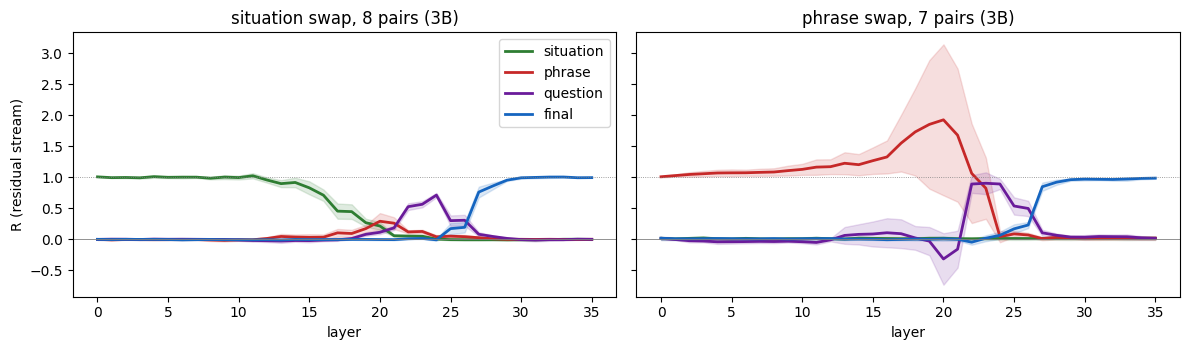

In [8]:
def run(e):
    ps = keep_correct(score_pairs(model, tok, pairs[e][:20]))[:8]
    assert len(ps) >= 4, f"only {len(ps)} correct pairs for {e}"
    return region_patching(model, tok, ps, kinds=("resid",), progress=False)["resid"]

R4 = {e: cached(f"region_resid_{e}_3B_8pairs", lambda e=e: run(e), sub="00_setup_check") for e in ["situation", "phrase"]}

cols = {"situation": "#2E7D32", "phrase": "#C62828", "question": "#6A1B9A", "final": "#1565C0"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (e, A) in zip(axes, R4.items()):
    m, se = mean_and_se(A)
    for j, r in enumerate(REGIONS):
        ax.plot(m[:, j], color=cols[r], lw=2, label=r)
        ax.fill_between(range(len(m)), m[:, j] - 1.96 * se[:, j], m[:, j] + 1.96 * se[:, j], color=cols[r], alpha=0.15)
    ax.axhline(0, c="gray", lw=0.6); ax.axhline(1, c="gray", lw=0.6, ls=":")
    ax.set_title(f"{e} swap, {len(A)} pairs (3B)"); ax.set_xlabel("layer")
axes[0].set_ylabel("R (residual stream)"); axes[0].legend()
plt.tight_layout(); plt.show()

# the final token must carry the answer at the last layer
CHECKS["4 final token at the end"] = all(mean_and_se(A)[0][-1, REGIONS.index("final")] > 0.8 for A in R4.values())

## Summary

In [9]:
for k, v in CHECKS.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
print("\nALL CHECKS PASSED" if all(CHECKS.values()) else "\nSOME CHECKS FAILED:")

FAIL  1 batched = single
PASS  2 accuracy as before
PASS  3a R=1 / R=0
PASS  3b heads = attention
PASS  4 final token at the end

SOME CHECKS FAILED: send the output to Claude
